<a href="https://colab.research.google.com/github/adecool/machine-learning---unsupervised-10-projects/blob/main/Customer_Segmentation_on_an_online_retail.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Online Retail.xlsx to Online Retail (1).xlsx


In [ ]:
import pandas as pd

df = pd.read_excel("Online Retail.xlsx")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:
print("Missing values:")
display(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

print("Unique customers:", df["CustomerID"].nunique())

Missing values:


,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


Duplicate rows: 5268
Unique customers: 4372


In [ ]:
total_rows = len(df)

missing_customers = df["CustomerID"].isna().sum()

missing_percentage = (
    missing_customers / total_rows
) * 100

print("Total rows:", total_rows)
print("Missing CustomerIDs:", missing_customers)
print("Percentage missing:", round(missing_percentage, 2), "%")

Total rows: 541909
Missing CustomerIDs: 135080
Percentage missing: 24.93 %


In [ ]:
missing_by_country = (
    df.groupby("Country")["CustomerID"]
    .agg(
        Total_Rows="size",
        Missing_IDs=lambda x: x.isna().sum()
    )
)

missing_by_country["Missing_Percentage"] = (
    missing_by_country["Missing_IDs"]
    / missing_by_country["Total_Rows"] * 100
)

display(
    missing_by_country.sort_values(
        "Missing_IDs", ascending=False
    ).head(10)
)

,Total_Rows,Missing_IDs,Missing_Percentage
Country,,,
United Kingdom,495478,133600,26.963861
EIRE,8196,711,8.674963
Hong Kong,288,288,100.000000
Unspecified,446,202,45.291480
Switzerland,2002,125,6.243756
France,8557,66,0.771298
Israel,297,47,15.824916
Portugal,1519,39,2.567479
Bahrain,19,2,10.526316


In [ ]:
# Identify cancelled invoices
cancelled = df[
    df["InvoiceNo"].astype(str).str.startswith("C")
]

print("Cancelled transaction lines:", len(cancelled))

print(
    "Unique cancelled invoices:",
    cancelled["InvoiceNo"].nunique()
)

print(
    "Negative quantities:",
    (df["Quantity"] < 0).sum()
)

print(
    "Zero or negative prices:",
    (df["UnitPrice"] <= 0).sum()
)

display(cancelled.head())

Cancelled transaction lines: 9288
Unique cancelled invoices: 3836
Negative quantities: 10624
Zero or negative prices: 2517


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [ ]:
negative_without_c = df[
    (df["Quantity"] < 0) &
    (~df["InvoiceNo"].astype(str).str.startswith("C"))
]

print(
    "Negative quantities without C:",
    len(negative_without_c)
)

display(negative_without_c.head(10))

Negative quantities without C: 1336


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7192,537000,21414,NaN,-22,2010-12-03 15:32:00,0.0,NaN,United Kingdom
7193,537001,21653,NaN,-6,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7195,537003,85126,NaN,-2,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7196,537004,21814,NaN,-30,2010-12-03 15:34:00,0.0,NaN,United Kingdom
7197,537005,21692,NaN,-70,2010-12-03 15:35:00,0.0,NaN,United Kingdom


In [ ]:
duplicate_records = df[
    df.duplicated(keep=False)
]

display(
    duplicate_records.sort_values(
        ["InvoiceNo", "StockCode"]
    ).head(15)
)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom


In [ ]:
# Create a copy of the original dataset
sales = df.copy()

# Keep transactions linked to customers
sales = sales.dropna(subset=["CustomerID"])

# Keep positive quantities and prices
sales = sales[
    (sales["Quantity"] > 0) &
    (sales["UnitPrice"] > 0)
]

# Exclude cancelled invoices
sales = sales[
    ~sales["InvoiceNo"].astype(str).str.startswith("C")
]

# Calculate the value of each transaction line
sales["TotalPrice"] = (
    sales["Quantity"] * sales["UnitPrice"]
)

print("Original rows:", len(df))
print("Cleaned rows:", len(sales))
print("Unique customers:", sales["CustomerID"].nunique())
print("Unique invoices:", sales["InvoiceNo"].nunique())

display(sales.head())

Original rows: 541909
Cleaned rows: 397884
Unique customers: 4338
Unique invoices: 18532


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [ ]:
print("First sale:", sales["InvoiceDate"].min())
print("Last sale:", sales["InvoiceDate"].max())

print(
    "Number of countries:",
    sales["Country"].nunique()
)

First sale: 2010-12-01 08:26:00
Last sale: 2011-12-09 12:50:00
Number of countries: 37


using RFM ANALYSIS for customer segmentation

In [ ]:
# Ensure InvoiceDate is a datetime column
sales["InvoiceDate"] = pd.to_datetime(
    sales["InvoiceDate"]
)

# Set reference date to one day after
# the last recorded transaction date
reference_date = (
    sales["InvoiceDate"].max().normalize()
    + pd.Timedelta(days=1)
)

print("Reference date:", reference_date)

# Find the most recent purchase for each customer
last_purchase = sales.groupby("CustomerID")[
    "InvoiceDate"
].max()

# Calculate recency in whole calendar days
recency = (
    reference_date - last_purchase.dt.normalize()
).dt.days

print("\nRecency summary:")
print(recency.describe())

print("\nSample customer recency values:")
display(recency.head(10))

Reference date: 2011-12-10 00:00:00

Recency summary:
count    4338.000000
mean       93.059474
std       100.012264
min         1.000000
25%        18.000000
50%        51.000000
75%       142.750000
max       374.000000
Name: InvoiceDate, dtype: float64

Sample customer recency values:


,InvoiceDate
CustomerID,
12346.0,326
12347.0,3
12348.0,76
12349.0,19
12350.0,311
12352.0,37
12353.0,205
12354.0,233
12355.0,215


In [ ]:
frequency = sales.groupby("CustomerID")[
    "InvoiceNo"
].nunique()

print("Frequency summary:")
print(frequency.describe())

print("\nSample customer frequencies:")
display(frequency.head(10))

Frequency summary:
count    4338.000000
mean        4.272015
std         7.697998
min         1.000000
25%         1.000000
50%         2.000000
75%         5.000000
max       209.000000
Name: InvoiceNo, dtype: float64

Sample customer frequencies:


,InvoiceNo
CustomerID,
12346.0,1
12347.0,7
12348.0,4
12349.0,1
12350.0,1
12352.0,8
12353.0,1
12354.0,1
12355.0,1


In [ ]:
print("Customers with 1 order:",
      (frequency == 1).sum())

print("Customers with more than 20 orders:",
      (frequency > 20).sum())

print("\nTop 10 customers by frequency:")
display(frequency.sort_values(ascending=False).head(10))

Customers with 1 order: 1493
Customers with more than 20 orders: 95

Top 10 customers by frequency:


,InvoiceNo
CustomerID,
12748.0,209
14911.0,201
17841.0,124
13089.0,97
14606.0,93
15311.0,91
12971.0,86
14646.0,73
16029.0,63


In [ ]:
sales["TotalPrice"] = (
    sales["Quantity"] * sales["UnitPrice"]
)

In [ ]:
monetary = sales.groupby("CustomerID")[
    "TotalPrice"
].sum()

print("Monetary summary:")
print(monetary.describe())

print("\nTop 10 customers by monetary value:")
display(monetary.sort_values(ascending=False).head(10))

Monetary summary:
count      4338.000000
mean       2054.266460
std        8989.230441
min           3.750000
25%         307.415000
50%         674.485000
75%        1661.740000
max      280206.020000
Name: TotalPrice, dtype: float64

Top 10 customers by monetary value:


,TotalPrice
CustomerID,
14646.0,280206.02
18102.0,259657.30
17450.0,194550.79
16446.0,168472.50
14911.0,143825.06
12415.0,124914.53
14156.0,117379.63
17511.0,91062.38
16029.0,81024.84


In [ ]:
rfm = pd.DataFrame({
    "Recency": recency,
    "Frequency": frequency,
    "Monetary": monetary
})

print("RFM dataset shape:", rfm.shape)

print("\nMissing values:")
print(rfm.isna().sum())

print("\nFirst 10 customers:")
display(rfm.head(10))

RFM dataset shape: (4338, 3)

Missing values:
Recency      0
Frequency    0
Monetary     0
dtype: int64

First 10 customers:


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,3,7,4310.00
12348.0,76,4,1797.24
12349.0,19,1,1757.55
12350.0,311,1,334.40
12352.0,37,8,2506.04
12353.0,205,1,89.00
12354.0,233,1,1079.40
12355.0,215,1,459.40


an unsual record for customer 12346

In [ ]:
customer_12346 = df[
    df["CustomerID"] == 12346
]

display(
    customer_12346[
        [
            "InvoiceNo",
            "StockCode",
            "Description",
            "Quantity",
            "UnitPrice",
            "InvoiceDate"
        ]
    ]
)

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,InvoiceDate
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,2011-01-18 10:01:00
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,2011-01-18 10:17:00


In [ ]:
# Use original records with identifiable customers
transactions = df.dropna(
    subset=["CustomerID"]
).copy()

# Calculate signed transaction values
transactions["TransactionValue"] = (
    transactions["Quantity"] *
    transactions["UnitPrice"]
)

# Calculate gross and net recorded values
gross_sales = transactions.loc[
    transactions["TransactionValue"] > 0,
    "TransactionValue"
].sum()

negative_values = transactions.loc[
    transactions["TransactionValue"] < 0,
    "TransactionValue"
].sum()

net_sales = transactions["TransactionValue"].sum()

print("Gross positive value:", round(gross_sales, 2))
print("Negative transaction value:", round(negative_values, 2))
print("Net recorded value:", round(net_sales, 2))

Gross positive value: 8911407.9
Negative transaction value: -611342.09
Net recorded value: 8300065.81


In [ ]:
net_monetary = transactions.groupby(
    "CustomerID"
)["TransactionValue"].sum()

print("Net monetary summary:")
print(net_monetary.describe())

print("\nCustomers with negative net value:")
print((net_monetary < 0).sum())

print("\nCustomers with zero net value:")
print((net_monetary == 0).sum())

print("\nCustomer 12346:")
print(net_monetary.loc[12346])

Net monetary summary:
count      4372.000000
mean       1898.459701
std        8219.345141
min       -4287.630000
25%         293.362500
50%         648.075000
75%        1611.725000
max      279489.020000
Name: TransactionValue, dtype: float64

Customers with negative net value:
42

Customers with zero net value:
8

Customer 12346:
0.0


In [ ]:
# Customers in the net analysis
net_customers = set(net_monetary.index)

# Customers in the original RFM dataset
rfm_customers = set(rfm.index)

# Customers missing from the original RFM dataset
additional_customers = (
    net_customers - rfm_customers
)

print(
    "Additional customers:",
    len(additional_customers)
)

# Inspect their net monetary values
display(
    net_monetary.loc[
        sorted(additional_customers)
    ].describe()
)

print("\nSample additional customers:")
display(
    net_monetary.loc[
        sorted(additional_customers)
    ].head(10)
)

Additional customers: 34


,TransactionValue
count,34.000000
mean,-306.212941
std,798.270591
min,-4287.630000
25%,-129.187500
50%,-31.125000
75%,-12.575000
max,0.000000



Sample additional customers:


,TransactionValue
CustomerID,
12503.0,-1126.00
12505.0,-4.50
12605.0,-7.50
12666.0,-227.44
12870.0,-14.90
12943.0,-3.75
13154.0,-611.86
13256.0,0.00
13693.0,-32.00


In [ ]:
# Align net monetary values with original RFM customers
rfm_net = rfm.copy()

rfm_net["NetMonetary"] = net_monetary.reindex(
    rfm_net.index
)

print("Original RFM customers:", len(rfm_net))

print(
    "Customers with positive net value:",
    (rfm_net["NetMonetary"] > 0).sum()
)

print(
    "Customers with zero net value:",
    (rfm_net["NetMonetary"] == 0).sum()
)

print(
    "Customers with negative net value:",
    (rfm_net["NetMonetary"] < 0).sum()
)

Original RFM customers: 4338
Customers with positive net value: 4322
Customers with zero net value: 7
Customers with negative net value: 9


In [ ]:
# Keep customers with positive net recorded value
rfm_model = rfm_net[
    rfm_net["NetMonetary"] > 0
].copy()

# Replace gross Monetary with net Monetary
rfm_model["Monetary"] = rfm_model["NetMonetary"]

# Keep the three RFM features
rfm_model = rfm_model[
    ["Recency", "Frequency", "Monetary"]
]

print("Final RFM shape:", rfm_model.shape)

print("\nMissing values:")
print(rfm_model.isna().sum())

print("\nSummary:")
display(rfm_model.describe())

Final RFM shape: (4322, 3)

Missing values:
Recency      0
Frequency    0
Monetary     0
dtype: int64

Summary:


,Recency,Frequency,Monetary
count,4322.000000,4322.000000,4.322000e+03
mean,92.748265,4.283434,1.923483e+03
std,99.816393,7.709908,8.263128e+03
min,1.000000,1.000000,1.776357e-15
25%,18.000000,1.000000,3.022925e+02
50%,51.000000,2.000000,6.575500e+02
75%,142.000000,5.000000,1.625740e+03
max,374.000000,209.000000,2.794890e+05


In [ ]:
# Round monetary values to the nearest penny
rfm_net["NetMonetary"] = rfm_net["NetMonetary"].round(2)

# Rebuild the modelling dataset
rfm_model = rfm_net.loc[
    rfm_net["NetMonetary"] > 0,
    ["Recency", "Frequency", "NetMonetary"]
].copy()

rfm_model = rfm_model.rename(
    columns={"NetMonetary": "Monetary"}
)

print("Updated RFM shape:", rfm_model.shape)
print("Minimum monetary:", rfm_model["Monetary"].min())

Updated RFM shape: (4317, 3)
Minimum monetary: 2.9


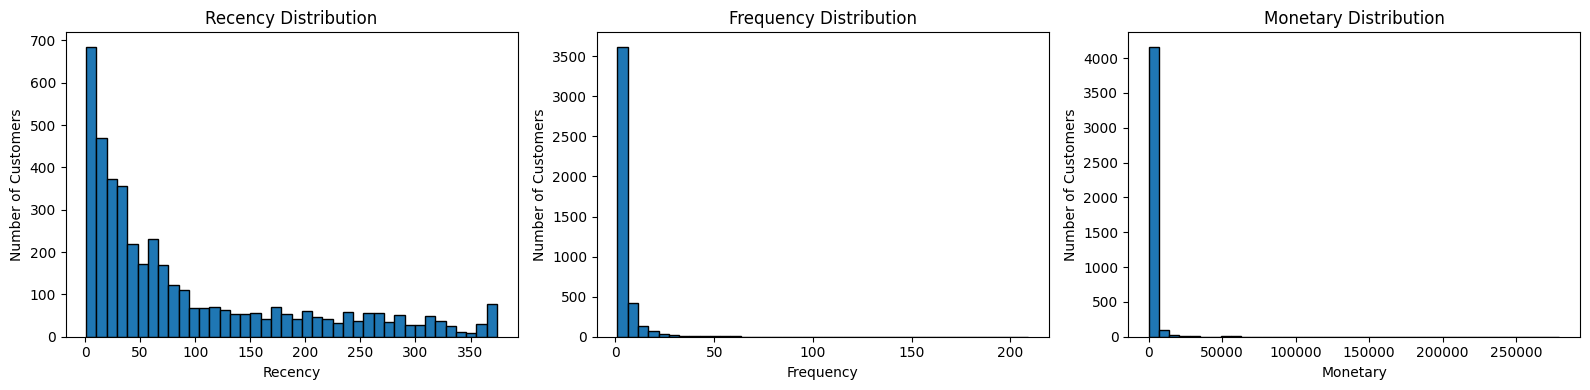

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

features = ["Recency", "Frequency", "Monetary"]

for ax, feature in zip(axes, features):
    ax.hist(rfm_model[feature], bins=40, edgecolor="black")
    ax.set_title(f"{feature} Distribution")
    ax.set_xlabel(feature)
    ax.set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()

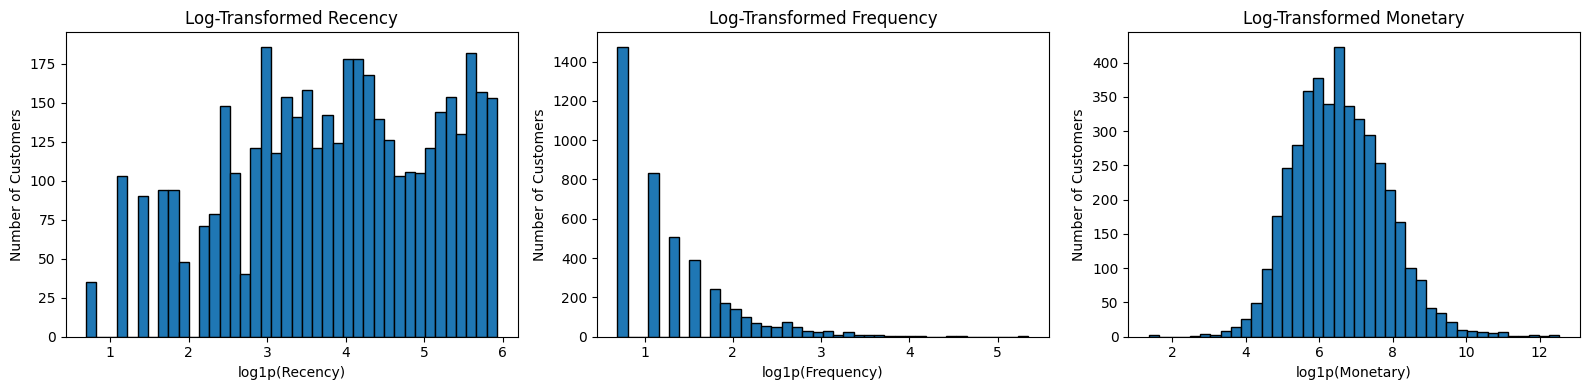

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Apply logarithmic transformation
rfm_log = np.log1p(rfm_model)

# Visualise transformed distributions
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, feature in zip(axes, rfm_log.columns):
    ax.hist(
        rfm_log[feature],
        bins=40,
        edgecolor="black"
    )

    ax.set_title(f"Log-Transformed {feature}")
    ax.set_xlabel(f"log1p({feature})")
    ax.set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Initialise the scaler
scaler = StandardScaler()

# Scale the log-transformed RFM data
rfm_scaled = pd.DataFrame(
    scaler.fit_transform(rfm_log),
    columns=rfm_log.columns,
    index=rfm_log.index
)

print("Scaled RFM summary:")
display(rfm_scaled.describe().round(3))

print("\nFirst five customers:")
display(rfm_scaled.head())

Scaled RFM summary:


,Recency,Frequency,Monetary
count,4317.000,4317.000,4317.000
mean,0.000,-0.000,-0.000
std,1.000,1.000,1.000
min,-2.417,-0.959,-4.190
25%,-0.695,-0.959,-0.689
50%,0.075,-0.366,-0.066
75%,0.849,0.649,0.661
max,1.586,5.852,4.799



First five customers:


,Recency,Frequency,Monetary
CustomerID,,,
12347.0,-1.887148,1.069682,1.444221
12348.0,0.375319,0.381889,0.741201
12349.0,-0.655944,-0.958992,0.723256
12350.0,1.445691,-0.958992,-0.608973
12352.0,-0.164932,1.242044,0.619894


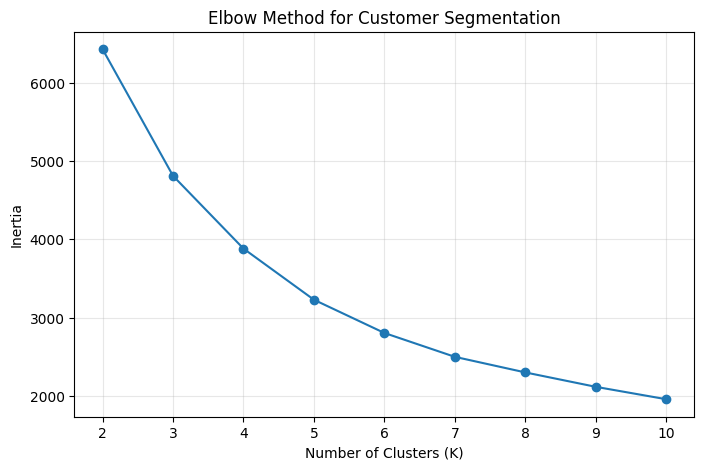

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertias = []

k_values = range(2, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(rfm_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(k_values, inertias, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Customer Segmentation")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)

plt.show()

DAY 3

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import pandas as pd

silhouette_scores = []

k_values = range(2, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(rfm_scaled)

    score = silhouette_score(rfm_scaled, labels)

    silhouette_scores.append(score)

    print(f"K = {k}: Silhouette Score = {score:.4f}")

K = 2: Silhouette Score = 0.4324
K = 3: Silhouette Score = 0.3381
K = 4: Silhouette Score = 0.3342
K = 5: Silhouette Score = 0.3186
K = 6: Silhouette Score = 0.3148
K = 7: Silhouette Score = 0.3043
K = 8: Silhouette Score = 0.2946
K = 9: Silhouette Score = 0.2812
K = 10: Silhouette Score = 0.2771


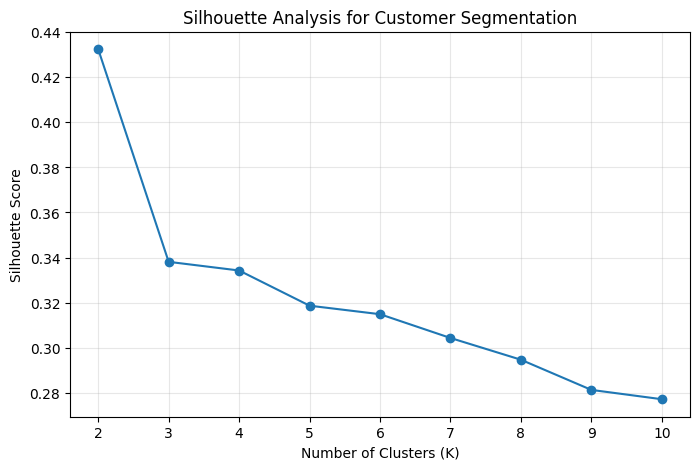

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis for Customer Segmentation")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)

plt.show()

In [ ]:
from sklearn.cluster import KMeans

for k in [2, 3, 4]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(rfm_scaled)

    # Use original RFM values for interpretation
    cluster_data = rfm_model.copy()

    cluster_data["Cluster"] = labels

    # Calculate customer profiles
    profile = cluster_data.groupby("Cluster").agg(
        Customers=("Recency", "size"),
        Recency=("Recency", "median"),
        Frequency=("Frequency", "median"),
        Monetary=("Monetary", "median"),
        Total_Monetary=("Monetary", "sum")
    )

    profile["Customer_%"] = (
        profile["Customers"] / len(cluster_data)
    ) * 100

    print(f"\nCustomer Profiles for K = {k}")

    display(profile.round(2))


Customer Profiles for K = 2


,Customers,Recency,Frequency,Monetary,Total_Monetary,Customer_%
Cluster,,,,,,
0,2656,96.0,1.0,357.48,1291200.55,61.52
1,1661,17.0,6.0,2024.95,7022094.40,38.48



Customer Profiles for K = 3


,Customers,Recency,Frequency,Monetary,Total_Monetary,Customer_%
Cluster,,,,,,
0,1872,159.0,1.0,290.91,673712.72,43.36
1,753,10.0,10.0,3626.81,5601359.45,17.44
2,1692,30.0,3.0,967.34,2038222.78,39.19



Customer Profiles for K = 4


,Customers,Recency,Frequency,Monetary,Total_Monetary,Customer_%
Cluster,,,,,,
0,1542,186.0,1.0,298.64,548692.40,35.72
1,715,9.0,10.0,3578.80,5382614.35,16.56
2,878,20.0,2.0,408.68,419561.39,20.34
3,1182,52.0,4.0,1327.18,1962426.81,27.38


In [ ]:
from sklearn.cluster import KMeans

final_model = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Train the model
labels = final_model.fit_predict(rfm_scaled)

# Create final customer segmentation dataset
rfm_final = rfm_model.copy()

rfm_final["Cluster"] = labels

# Assign business-friendly segment names
segment_names = {
    0: "Dormant Customers",
    1: "High-Value Frequent Customers",
    2: "Recent Low-Engagement Customers",
    3: "Established Repeat Customers"
}

rfm_final["Segment"] = rfm_final["Cluster"].map(
    segment_names
)

display(rfm_final.head(10))

,Recency,Frequency,Monetary,Cluster,Segment
CustomerID,,,,,
12347.0,3,7,4310.00,1,High-Value Frequent Customers
12348.0,76,4,1797.24,3,Established Repeat Customers
12349.0,19,1,1757.55,2,Recent Low-Engagement Customers
12350.0,311,1,334.40,0,Dormant Customers
12352.0,37,8,1545.41,3,Established Repeat Customers
12353.0,205,1,89.00,0,Dormant Customers
12354.0,233,1,1079.40,0,Dormant Customers
12355.0,215,1,459.40,0,Dormant Customers
12356.0,23,3,2811.43,3,Established Repeat Customers


In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# Reduce three dimensions to two
pca = PCA(n_components=2)

pca_result = pca.fit_transform(rfm_scaled)

# Store the principal components
rfm_final["PC1"] = pca_result[:, 0]
rfm_final["PC2"] = pca_result[:, 1]

# Check explained variance
print("Explained variance:",
      pca.explained_variance_ratio_)

print("Total explained variance:",
      pca.explained_variance_ratio_.sum())

Explained variance: [0.75316135 0.18683664]
Total explained variance: 0.9399979924205315


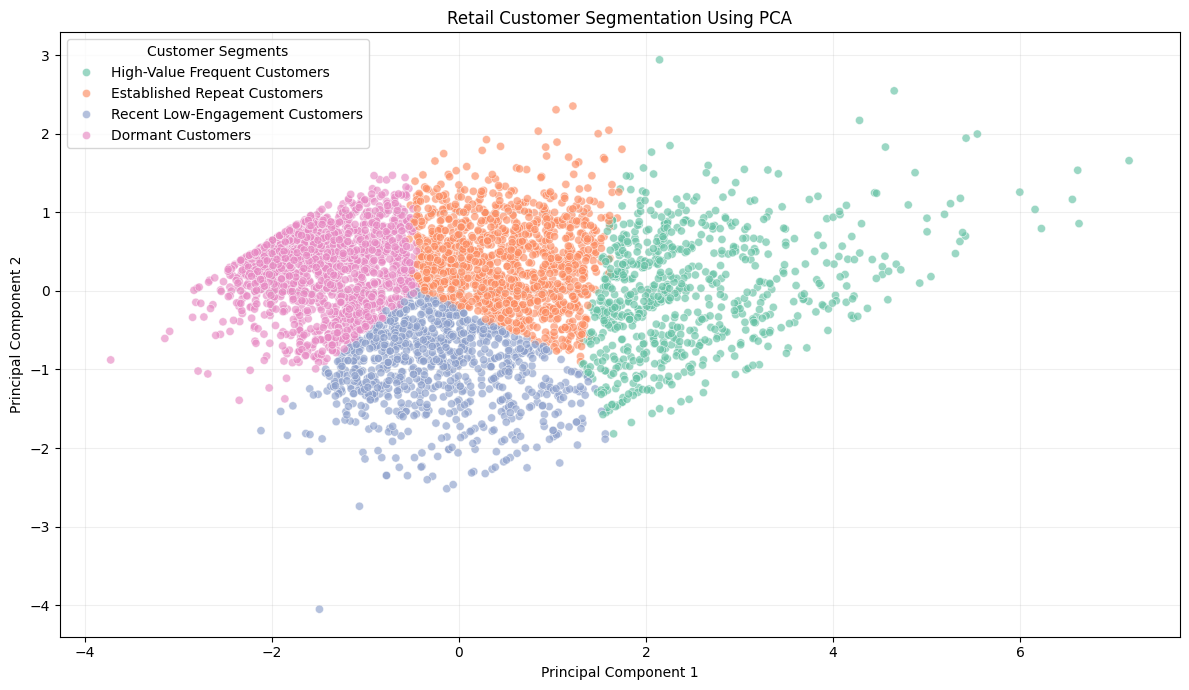

In [ ]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=rfm_final,
    x="PC1",
    y="PC2",
    hue="Segment",
    palette="Set2",
    alpha=0.65,
    s=35
)

plt.title("Retail Customer Segmentation Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Customer Segments")
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [ ]:
# Examine the weight of each original feature
# in each principal component

pca_weights = pd.DataFrame(
    pca.components_.T,
    index=rfm_scaled.columns,
    columns=["PC1", "PC2"]
)

display(pca_weights.round(4))

,PC1,PC2
Recency,-0.5117,0.8508
Frequency,0.6174,0.2675
Monetary,0.5974,0.4523


In [ ]:
# Select one customer
customer = rfm_scaled.loc[12347]

# Centre the customer's features
customer_centered = customer.values - pca.mean_

# Manually calculate principal component scores
manual_pca = customer_centered @ pca.components_.T

print("Original scaled features:")
print(customer)

print("\nManually calculated PCA scores:")
print(manual_pca)

print("\nSklearn PCA scores:")
print(rfm_final.loc[12347, ["PC1", "PC2"]])

Original scaled features:
Recency     -1.887148
Frequency    1.069682
Monetary     1.444221
Name: 12347.0, dtype: float64

Manually calculated PCA scores:
[ 2.48897419 -0.66619094]

Sklearn PCA scores:
PC1    2.488974
PC2   -0.666191
Name: 12347.0, dtype: object


In [ ]:
segment_analysis = rfm_final.groupby("Segment").agg(
    Customers=("Recency", "size"),
    Median_Recency=("Recency", "median"),
    Median_Frequency=("Frequency", "median"),
    Median_Monetary=("Monetary", "median"),
    Average_Monetary=("Monetary", "mean"),
    Total_Monetary=("Monetary", "sum")
)

segment_analysis["Customer_Share_%"] = (
    segment_analysis["Customers"] /
    segment_analysis["Customers"].sum()
) * 100

segment_analysis["Monetary_Share_%"] = (
    segment_analysis["Total_Monetary"] /
    segment_analysis["Total_Monetary"].sum()
) * 100

segment_analysis["Value_Index"] = (
    segment_analysis["Monetary_Share_%"] /
    segment_analysis["Customer_Share_%"]
)

display(
    segment_analysis.sort_values(
        "Value_Index",
        ascending=False
    ).round(2)
)

,Customers,Median_Recency,Median_Frequency,Median_Monetary,Average_Monetary,Total_Monetary,Customer_Share_%,Monetary_Share_%,Value_Index
Segment,,,,,,,,,
High-Value Frequent Customers,715,9.0,10.0,3578.80,7528.13,5382614.35,16.56,64.75,3.91
Established Repeat Customers,1182,52.0,4.0,1327.18,1660.26,1962426.81,27.38,23.61,0.86
Recent Low-Engagement Customers,878,20.0,2.0,408.68,477.86,419561.39,20.34,5.05,0.25
Dormant Customers,1542,186.0,1.0,298.64,355.83,548692.40,35.72,6.60,0.18


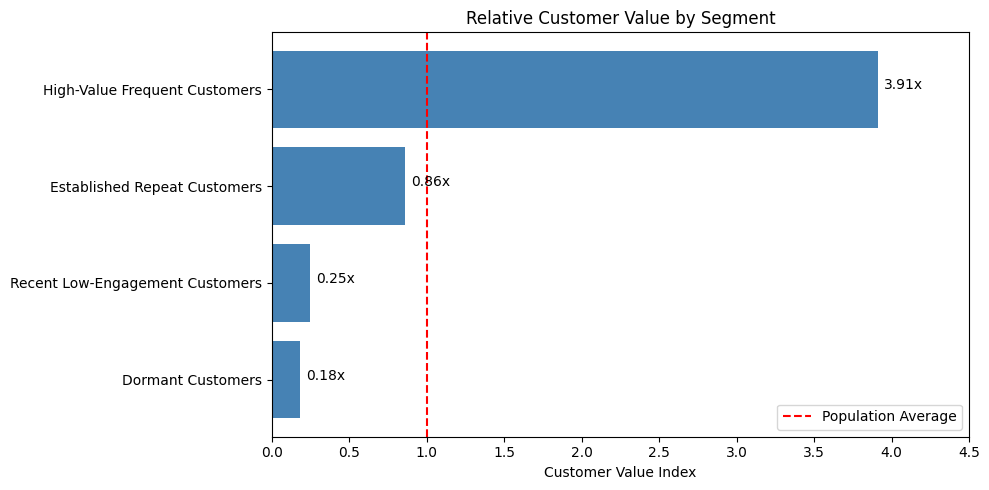

In [ ]:
import matplotlib.pyplot as plt

value_plot = segment_analysis.sort_values(
    "Value_Index"
)

plt.figure(figsize=(10, 5))

plt.barh(
    value_plot.index,
    value_plot["Value_Index"],
    color="steelblue"
)

plt.axvline(
    x=1,
    color="red",
    linestyle="--",
    label="Population Average"
)

for i, value in enumerate(value_plot["Value_Index"]):
    plt.text(value + 0.04, i, f"{value:.2f}x")

plt.xlabel("Customer Value Index")
plt.title("Relative Customer Value by Segment")
plt.xlim(0, 4.5)
plt.legend()
plt.tight_layout()
plt.show()

## Conclusion

This project investigated customer purchasing behaviour using Recency, Frequency and Monetary (RFM) analysis and K-Means clustering to support data-driven customer relationship management.

Following data cleaning, transaction investigation, feature engineering and preprocessing, 4,317 customers were segmented into four distinct behavioural groups.

Although the two-cluster solution produced the highest Silhouette Score of 0.4324, the four-cluster solution was selected for its greater business interpretability and potential for targeted customer engagement, with a Silhouette Score of 0.3342.

Principal Component Analysis retained approximately 94% of the variance in the transformed and standardised RFM features using two principal components, enabling effective visualisation of the customer segments.

The analysis revealed a substantial concentration of customer value. High-value frequent customers represented only 16.56% of the modelling population but contributed 64.75% of its total net monetary value. Conversely, dormant customers represented 35.72% of the population but contributed only 6.60%.

The findings demonstrate how unsupervised learning can transform historical transaction records into meaningful customer profiles that inform customer retention, personalised marketing, customer development and resource allocation.

Rather than applying a uniform marketing strategy to all customers, the business can use these behavioural segments to design and evaluate targeted interventions.

In [ ]:
# Export individual customer segments
rfm_final.to_csv(
    "customer_segmentation_results.csv"
)

# Export business intelligence summary
segment_analysis.to_csv(
    "customer_segment_summary.csv"
)

In [ ]:
import joblib

joblib.dump(
    {
        "model": final_model,
        "scaler": scaler,
        "pca": pca,
        "segment_names": segment_names,
        "reference_date": reference_date,
        "features": ["Recency", "Frequency", "Monetary"]
    },
    "customer_segmentation_model.pkl"
)

['customer_segmentation_model.pkl']

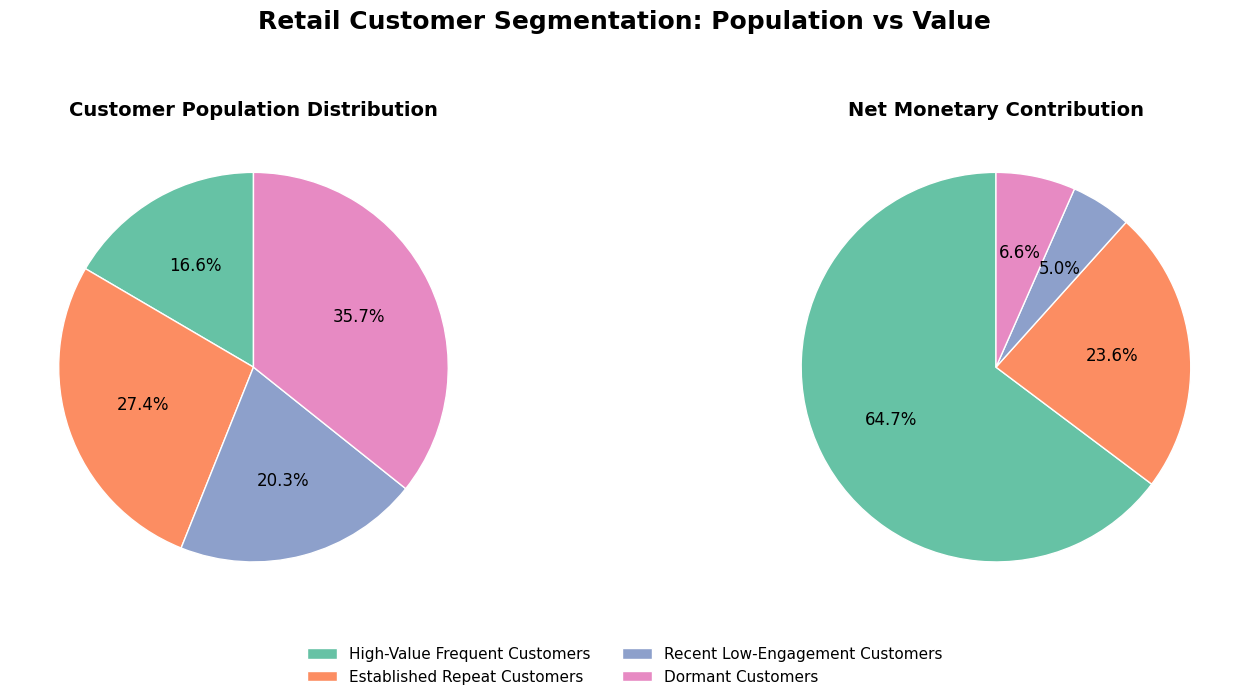

In [ ]:
import matplotlib.pyplot as plt

segments = [
    "High-Value Frequent Customers",
    "Established Repeat Customers",
    "Recent Low-Engagement Customers",
    "Dormant Customers"
]

pie_data = segment_analysis.loc[segments]

colors = [
    "#66c2a5",
    "#fc8d62",
    "#8da0cb",
    "#e78ac3"
]

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

# Customer population pie chart
axes[0].pie(
    pie_data["Customers"],
    colors=colors,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"edgecolor": "white"},
    textprops={"fontsize": 12}
)

axes[0].set_title(
    "Customer Population Distribution",
    fontsize=14,
    fontweight="bold"
)

# Net monetary contribution pie chart
axes[1].pie(
    pie_data["Total_Monetary"],
    colors=colors,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"edgecolor": "white"},
    textprops={"fontsize": 12}
)

axes[1].set_title(
    "Net Monetary Contribution",
    fontsize=14,
    fontweight="bold"
)

fig.suptitle(
    "Retail Customer Segmentation: Population vs Value",
    fontsize=18,
    fontweight="bold"
)

fig.legend(
    segments,
    loc="lower center",
    ncol=2,
    fontsize=11,
    frameon=False
)

plt.tight_layout(rect=[0, 0.10, 1, 0.92])

plt.savefig(
    "customer_value_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Customer Value Analysis and Strategic Marketing Recommendations

**To:** Board of Directors  
**From:** Data Analytics Team  
**Subject:** Customer Segmentation and Strategic Marketing Resource Allocation

## Executive summary

An analysis of 4,317 retail customers, representing approximately £8.31 million in historical net monetary value, has revealed significant differences in purchasing behaviour and customer contribution.

Using RFM analysis and K-Means clustering, four customer segments were identified. The findings suggest that adopting a uniform customer engagement strategy may not be the most effective approach to allocating marketing resources.

Most notably, 16.56% of customers contributed approximately 64.75% of total net monetary value, while the largest customer segment, representing 35.72% of customers, contributed only 6.60%.

These findings provide a basis for differentiated customer engagement strategies.

## Strategic decisions recommended to the board

**Decision 1: Prioritise the retention of high-value customers.**

The company should establish targeted retention initiatives for its 715 high-value frequent customers, whose combined historical net monetary contribution exceeds £5.38 million.

Recommended interventions include personalised customer service, loyalty programmes and monitoring changes in purchasing behaviour.

**Decision 2: Develop established customers into stronger purchasing segments.**

The 1,182 established customers represent a potential growth opportunity. Their demonstrated purchasing history provides a basis for testing cross-selling, product recommendations and repeat-purchase incentives.

**Decision 3: Encourage additional purchases among recently active customers.**

The company should introduce targeted follow-up campaigns for recent low-engagement customers, taking advantage of their relatively recent interaction with the business.

**Decision 4: Adopt a controlled approach to dormant customer reactivation.**

Although dormant customers represent the largest segment, their historical financial contribution is comparatively low. Reactivation campaigns should initially be conducted on a limited scale to establish their economic viability.

## Proposed pilot marketing budget

For an illustrative £10,000 marketing budget, the following allocation is recommended for initial testing:

| Customer segment | Allocation |
|---|---:|
| High-value frequent customers | £3,000 |
| Established repeat customers | £3,000 |
| Recent low-engagement customers | £3,000 |
| Dormant customers | £1,000 |
| **Total** | **£10,000** |

This allocation balances customer retention, customer development and reactivation. It represents a proposed pilot rather than a mathematically optimised budget.

## Performance monitoring

The effectiveness of these strategies should be evaluated using customer retention rates, repeat-purchase rates, purchasing frequency, incremental profit and return on marketing investment.

Controlled experiments should be conducted before expanding marketing expenditure.

## Board approval requested

The board is requested to approve a pilot segment-based marketing programme, establish appropriate performance indicators and review campaign outcomes before committing additional resources.

The objective is to move from generalised customer engagement towards a measurable, evidence-based approach to customer relationship management.